In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.metrics import f1_score
import mlens

# Load in original data and separate out x and y
combined_augmented_data = pd.read_csv("Embedded_FS/combined_augmented_data.csv")
aug_colnames = combined_augmented_data.columns
augmented_x = combined_augmented_data[aug_colnames[3:len(aug_colnames)]]
augmented_y = combined_augmented_data['target_vector']

# Create dataset with only conc values between 0.1 and 100 - this is sort of a baseline data set where I remove some of the "gimme" observations at high concentrations
# and don't quite remove all the low concentration values. I really don't think there's any signal below 
medium_trimmed_augmented_data = combined_augmented_data[(combined_augmented_data['Conc.']<126) & (combined_augmented_data['Conc.']>0.9)]
medium_trimmed_x = medium_trimmed_augmented_data[aug_colnames[3:len(aug_colnames)]]
medium_trimmed_y = medium_trimmed_augmented_data['target_vector']



>lr 0.511 (0.059)
>knn 0.511 (0.052)
>RF 0.562 (0.048)
>svm 0.542 (0.054)
>stacking 0.557 (0.045)


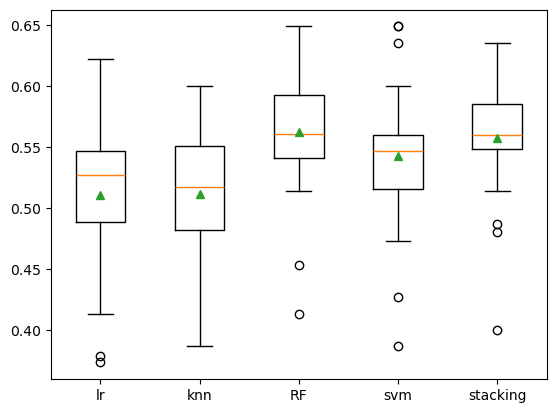

>lr 0.810 (0.075)
>knn 0.810 (0.084)
>RF 0.807 (0.079)
>svm 0.834 (0.065)
>stacking 0.829 (0.063)


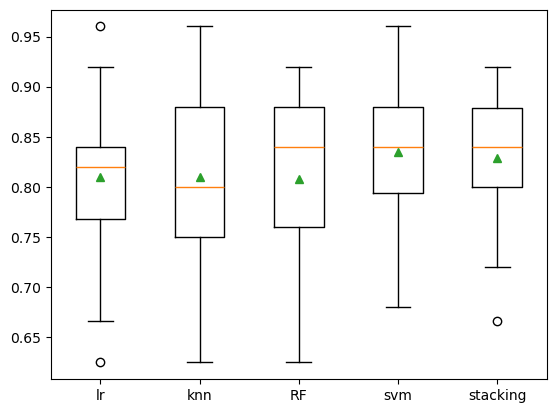

In [18]:
# First we can evaluate the performance of an assortment of classifiers to see how uncorrelated their performances are
# # I think this needs to be adapted pretty heavily to give each model a better chance - I'm not sure how much hyperparameter tuning is going on here

# Overall, this may be kind of a simplistic interpretation of a stacking classifier but it doesn't seem to be doing any better than the best classifier for any given dataset
# You can change StandardScaler to PoweverScaler and set PowerTransformer to Yeo-Johnson
def get_models():
    models = dict()
    models['lr'] = make_pipeline(StandardScaler(),
                                 LogisticRegression())
    models['knn'] = make_pipeline(StandardScaler(),
                                  PCA(),
                                  KNeighborsClassifier())
    models['RF'] = RandomForestClassifier()
    models['svm'] = make_pipeline(StandardScaler(),
                                #   PCA(),
                                  SVC())
    models['stacking'] = get_stacking()
    return models

def evaluate_model(model, X, y):
    cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
    scores = cross_val_score(model, X, y, scoring = 'accuracy', cv=cv, n_jobs=-1, error_score='raise')
    return scores

def get_stacking():
    # Define base models
    level0 = list()
    level0.append(('lr', make_pipeline(StandardScaler(),
                                 LogisticRegression(multi_class='multinomial'))))
    level0.append(('rf', RandomForestClassifier()))
    level0.append(('svm', make_pipeline(StandardScaler(),
                                  SVC())))
    level0.append(('knn', make_pipeline(StandardScaler(),
                                  KNeighborsClassifier())))

    # Define the meta learner model - here we leave the solver as 
    level1 = make_pipeline(StandardScaler(),
                           LogisticRegression(multi_class='multinomial'))
    
    # Define the stacking ensemble
    model = StackingClassifier(estimators=level0, final_estimator=level1, cv=5)
    return model

def multiple_model_evaluator(X, y):
    models = get_models()
    results, names = list(), list()
    for name, model in models.items():
        scores = evaluate_model(model, X, y)
        results.append(scores)
        names.append(name)
        print('>%s %.3f (%.3f)' % (name, np.mean(scores), np.std(scores)))

    plt.boxplot(results, labels=names, showmeans=True)
    plt.show()

multiple_model_evaluator(augmented_x, augmented_y)
multiple_model_evaluator(medium_trimmed_x, medium_trimmed_y)


In [ ]:
# Logistic regression and svm parameter tuning

In [ ]:
# Superlearner